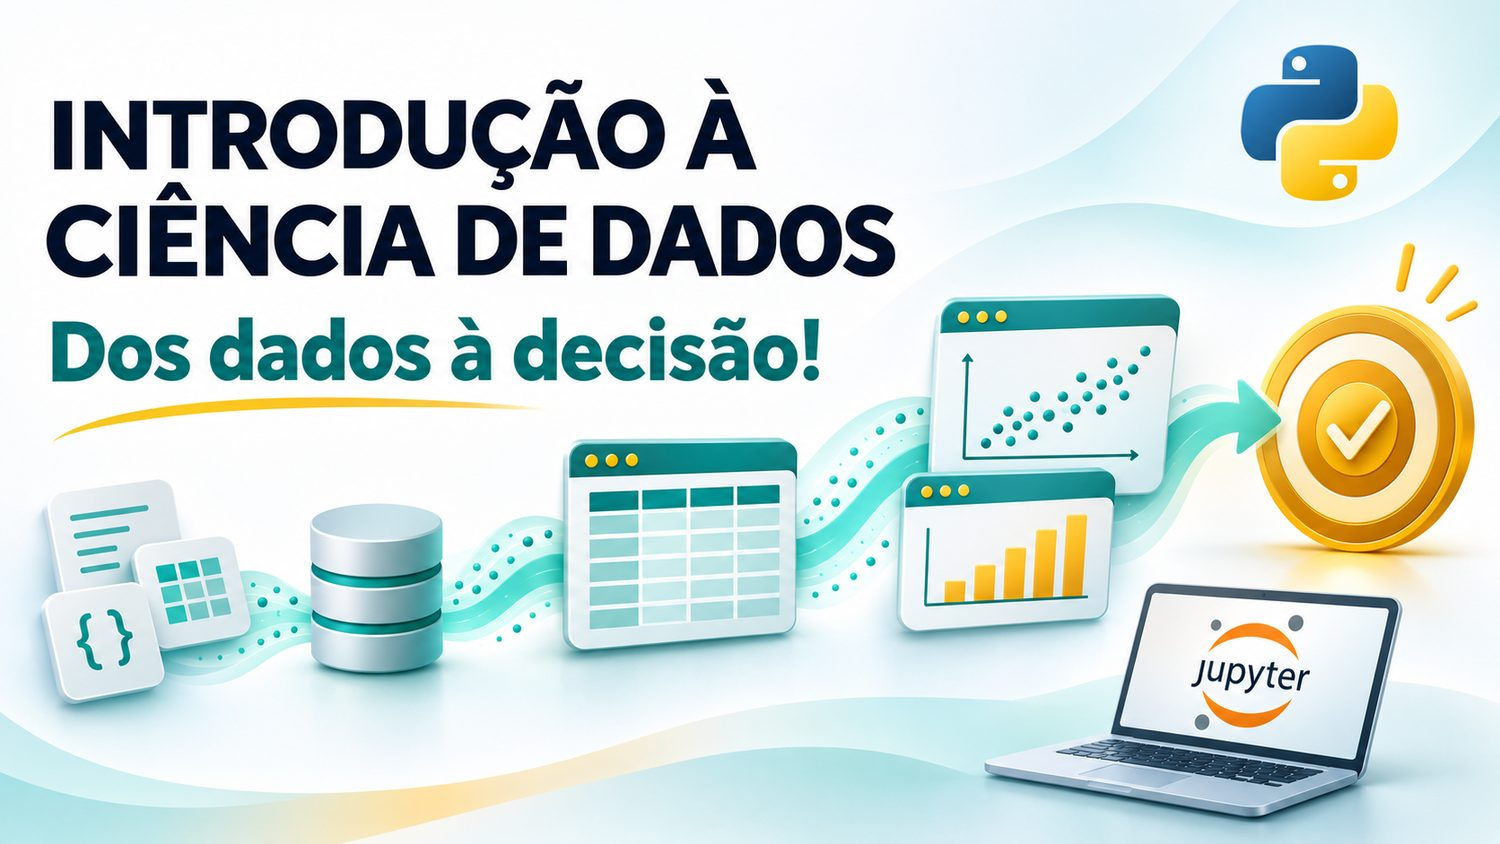

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/08_Boosting.ipynb)

# Capítulo 8 – Boosting

Uma floresta treina muitas árvores **independentes** e faz a média. O **boosting** segue a estratégia oposta: treina árvores **em sequência**, e cada uma tenta corrigir os erros das anteriores. Em vez de muitos modelos complexos que se compensam, usa muitos modelos simples que se somam. É a família de modelos que mais vezes dá os melhores resultados em dados tabulares. Este capítulo constrói um *gradient boosting* de raiz.

> **Objetivos:** perceber a ideia de corrigir erros em sequência; implementar o *gradient boosting* para regressão; perceber o papel da taxa de aprendizagem e do número de árvores; reconhecer o sobreajuste e travá-lo com paragem antecipada; usar as implementações do scikit-learn; comparar boosting e bagging; escolher entre os modelos do módulo.

**Pré-requisitos:** capítulos 4 a 7, e o capítulo 2 do módulo 5 (descida do gradiente).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## A ideia: aprender com os erros

No fim do capítulo anterior ficou um caso por resolver: o bagging quase não melhora árvores muito pequenas, porque elas erram todas da mesma maneira. Têm **viés**, e a média não tira viés.

O boosting ataca precisamente o viés. O raciocínio:

1. começa-se com uma previsão muito simples (a média do alvo);
2. calculam-se os **resíduos**: o que falta à previsão atual para acertar;
3. treina-se uma árvore pequena para **prever esses resíduos**;
4. soma-se à previsão uma fração do que a árvore diz;
5. volta-se ao passo 2.

Cada árvore, sozinha, é fraca. A soma de centenas de pequenas correções é um modelo forte.

Voltamos ao mundo simulado dos capítulos 5 e 7.

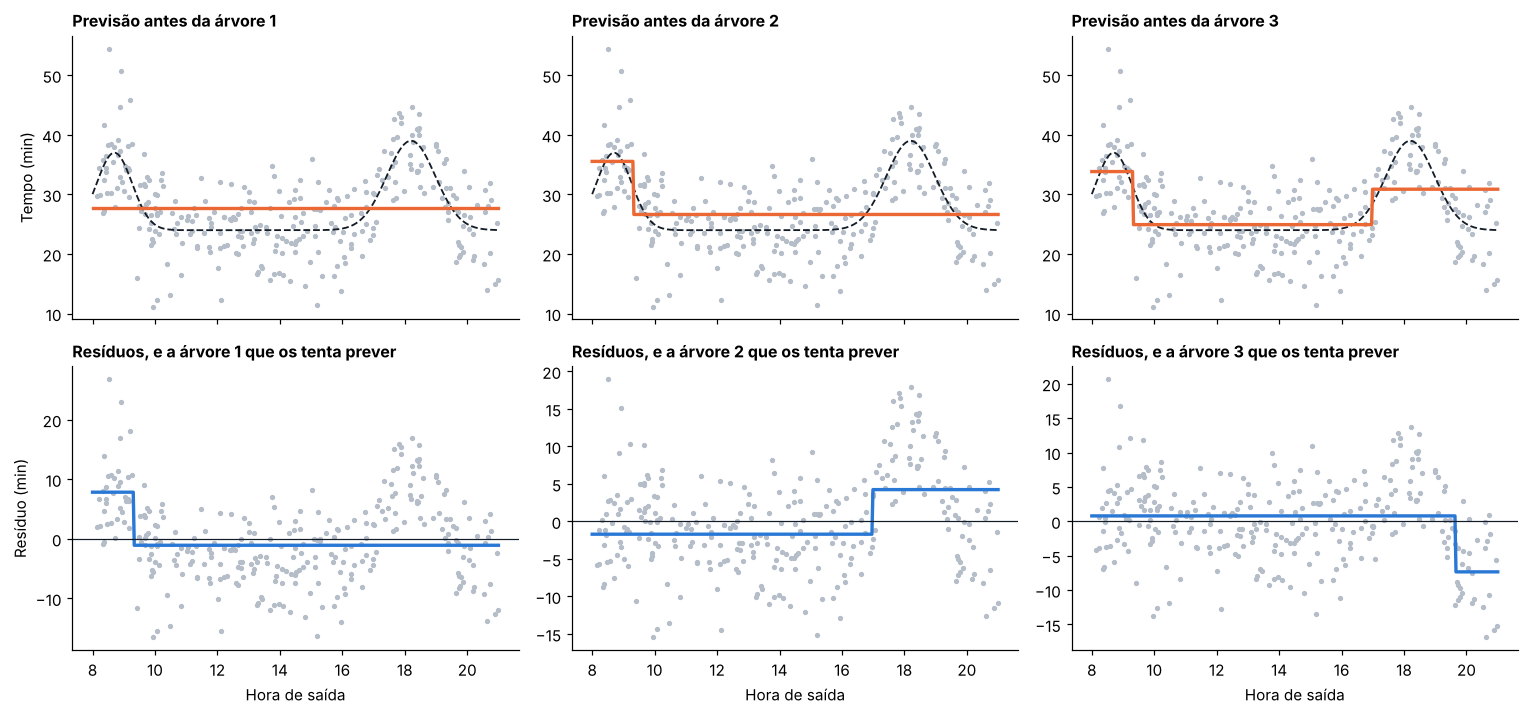

In [2]:
from sklearn.tree import DecisionTreeRegressor


def tempo_esperado(hora):
    hora = np.asarray(hora, dtype=float)
    return 24 + 13 * np.exp(-((hora - 8.7) / 0.8) ** 2) + 15 * np.exp(-((hora - 18.2) / 1.1) ** 2)


def amostrar(n, rng, ruido=5.0):
    hora = np.sort(rng.uniform(8, 21, n))
    return hora.reshape(-1, 1), tempo_esperado(hora) + rng.normal(0, ruido, n)


horas = np.linspace(8, 21, 400).reshape(-1, 1)
verdade = tempo_esperado(horas.ravel())
X1, y1 = amostrar(300, np.random.default_rng(11))

previsao = np.full(len(y1), y1.mean())                        # passo 1: a média
curva = np.full(len(horas), y1.mean())
fig, eixos = plt.subplots(2, 3, figsize=(14, 6.6), sharex=True)
for coluna in range(3):
    residuos = y1 - previsao                                  # passo 2: o que falta
    arvore = DecisionTreeRegressor(max_depth=1).fit(X1, residuos)        # passo 3: uma árvore pequena para os resíduos
    em_cima, em_baixo = eixos[0, coluna], eixos[1, coluna]
    em_cima.scatter(X1, y1, s=6, color=CINZA)
    em_cima.plot(horas, verdade, color=TINTA, ls="--", lw=1.2)
    em_cima.plot(horas, curva, color=LARANJA, lw=2.2)
    em_cima.set_title(f"Previsão antes da árvore {coluna + 1}", fontsize=10.5)
    em_baixo.scatter(X1, residuos, s=6, color=CINZA)
    em_baixo.plot(horas, arvore.predict(horas), color=AZUL, lw=2.2)
    em_baixo.axhline(0, color=TINTA, lw=0.8)
    em_baixo.set_title(f"Resíduos, e a árvore {coluna + 1} que os tenta prever", fontsize=10.5)
    em_baixo.set_xlabel("Hora de saída")
    previsao = previsao + arvore.predict(X1)                  # passo 4: somar a correção
    curva = curva + arvore.predict(horas)
eixos[0, 0].set_ylabel("Tempo (min)")
eixos[1, 0].set_ylabel("Resíduo (min)")
plt.tight_layout()
plt.show()

Em cima, a previsão acumulada (laranja); em baixo, o que lhe falta (os resíduos) e a árvore de uma só pergunta que os tenta prever (azul).

- A primeira previsão é uma linha horizontal. Os resíduos mostram as duas horas de ponta por explicar, e a primeira árvore apanha uma delas.
- Depois de somada essa correção, os resíduos mudam: a segunda árvore vai buscar o que ficou.
- E assim sucessivamente. Cada árvore trabalha num problema diferente: **o que as anteriores não conseguiram**.

Uma árvore de profundidade 1 só consegue dois patamares. Três delas, somadas, já fazem quatro. Com cem, a soma aproxima uma curva qualquer.

## Gradient boosting de raiz

Falta um ingrediente. Em vez de somar a correção inteira de cada árvore, soma-se só uma **fração**, a **taxa de aprendizagem**. Passos pequenos, muitas vezes: é a descida do gradiente do módulo 5, com uma diferença. Lá, cada passo ajustava os coeficientes; aqui, cada passo acrescenta uma árvore.

(O nome vem daí: para o erro quadrático, os resíduos são o gradiente do erro em relação às previsões, com o sinal trocado. Cada árvore aponta o sentido em que as previsões devem mexer.)

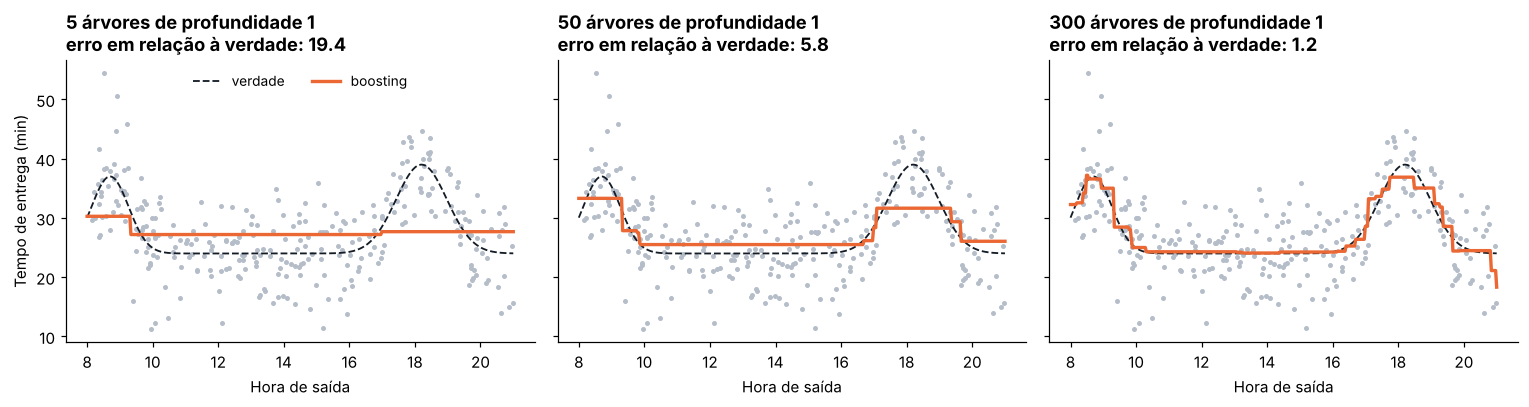

In [3]:
def boosting(X, y, n_arvores=100, taxa=0.1, profundidade=2):
    """Gradient boosting para regressão, com erro quadrático. Devolve (valor inicial, lista de árvores)."""
    X, y = np.asarray(X), np.asarray(y, dtype=float)
    inicial = y.mean()
    previsao = np.full(len(y), inicial)
    arvores = []
    for _ in range(n_arvores):
        arvore = DecisionTreeRegressor(max_depth=profundidade, random_state=0).fit(X, y - previsao)     # aprende os resíduos
        previsao = previsao + taxa * arvore.predict(X)                                                     # um pequeno passo
        arvores.append(arvore)
    return inicial, arvores


def prever_boosting(modelo, X, taxa=0.1, n_arvores=None):
    inicial, arvores = modelo
    X = np.asarray(X)
    return inicial + taxa * sum(arvore.predict(X) for arvore in arvores[:n_arvores])


modelo_1d = boosting(X1, y1, n_arvores=300, taxa=0.1, profundidade=1)
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, n in zip(eixos, [5, 50, 300]):
    curva = prever_boosting(modelo_1d, horas, n_arvores=n)
    ax.scatter(X1, y1, s=5, color=CINZA)
    ax.plot(horas, verdade, color=TINTA, ls="--", lw=1.2, label="verdade")
    ax.plot(horas, curva, color=LARANJA, lw=2.2, label="boosting")
    ax.set_title(f"{n} árvores de profundidade 1\nerro em relação à verdade: {np.mean((curva - verdade) ** 2):.1f}")
    ax.set_xlabel("Hora de saída")
eixos[0].set_ylabel("Tempo de entrega (min)")
eixos[0].legend(frameon=False, loc="upper center", ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

Com cinco árvores, a previsão mal saiu da média. Com cinquenta, as duas horas de ponta estão lá. Cada árvore é do tipo que, no capítulo anterior, o bagging não conseguia aproveitar; em sequência, cada uma a corrigir as anteriores, chegam a um modelo flexível.

Confirmamos com o scikit-learn:

In [4]:
from sklearn.ensemble import GradientBoostingRegressor

oficial = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=1, random_state=0).fit(X1, y1)
print(f"Maior diferença entre as nossas previsões e as do scikit-learn: {np.abs(prever_boosting(modelo_1d, horas) - oficial.predict(horas)).max():.6f} min")

Maior diferença entre as nossas previsões e as do scikit-learn: 0.000000 min


## Aqui, mais árvores **podem** sobreajustar

Numa floresta, juntar árvores nunca prejudica. No boosting é diferente: cada árvore nova ajusta-se um pouco mais aos dados de treino, e a partir de certo ponto o que resta nos resíduos é só **ruído**. Continuar é aprendê-lo.

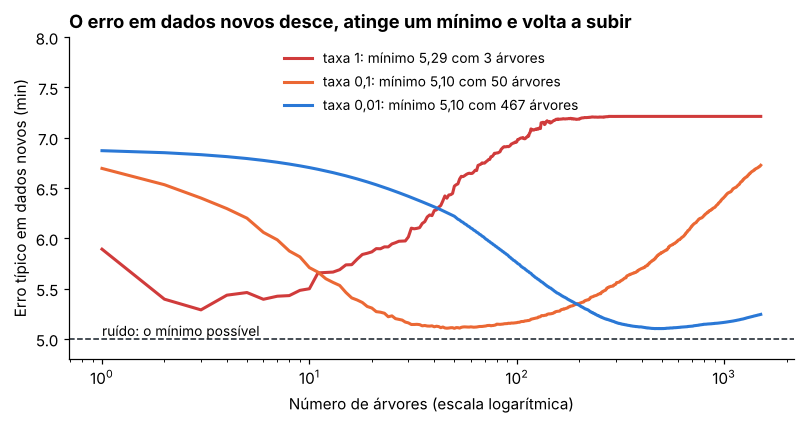

In [5]:
X_novo, y_novo = amostrar(5000, np.random.default_rng(99))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for taxa, cor in [(1.0, MAU), (0.1, LARANJA), (0.01, AZUL)]:
    modelo = GradientBoostingRegressor(n_estimators=1500, learning_rate=taxa, max_depth=2, random_state=0).fit(X1, y1)
    erro_novo = [np.sqrt(np.mean((y_novo - p) ** 2)) for p in modelo.staged_predict(X_novo)]
    ax.plot(range(1, 1501), erro_novo, color=cor, lw=2, label=f"taxa {taxa:g}: mínimo {min(erro_novo):.2f} com {int(np.argmin(erro_novo)) + 1} árvores".replace(".", ","))
ax.axhline(5, color=TINTA, ls="--", lw=1)
ax.text(1, 5.03, "ruído: o mínimo possível", ha="left", fontsize=9)
ax.set_xscale("log")
ax.set_ylim(4.8, 8)
ax.set_xlabel("Número de árvores (escala logarítmica)")
ax.set_ylabel("Erro típico em dados novos (min)")
ax.set_title("O erro em dados novos desce, atinge um mínimo e volta a subir")
ax.legend(frameon=False, loc="upper center", fontsize=9)
plt.show()

As três curvas têm a forma em «U» do capítulo 5: o número de árvores é a **complexidade** do modelo.

- Com uma taxa de **1** (somar cada correção inteira), o mínimo chega logo e é o pior dos três: os passos são tão grandes que o modelo salta por cima da boa solução e começa a ajustar ruído.
- Com **0,1**, o mínimo é mais baixo e chega mais tarde.
- Com **0,01**, chega-se ao mesmo mínimo, com cerca de dez vezes mais árvores; em troca, a subida depois do mínimo é muito mais lenta.

A taxa de aprendizagem e o número de árvores andam juntos: **taxa menor, mais árvores**. Uma taxa pequena com muitas árvores dá um resultado igual ou um pouco melhor, é mais tolerante a um número de árvores mal escolhido, e custa mais tempo.

### Paragem antecipada

Não é preciso adivinhar o número de árvores. Guarda-se uma parte dos dados para validação, vigia-se o erro à medida que se acrescentam árvores, e **para-se quando deixa de melhorar**.

In [6]:
com_paragem = GradientBoostingRegressor(n_estimators=2000, learning_rate=0.05, max_depth=2, validation_fraction=0.2, n_iter_no_change=20, random_state=0).fit(X1, y1)
print(f"Pedidas: 2000 árvores | usadas: {com_paragem.n_estimators_} (parou depois de 20 árvores seguidas sem melhorar na validação interna)")
print(f"Erro típico em dados novos: {np.sqrt(np.mean((y_novo - com_paragem.predict(X_novo)) ** 2)):.2f} min")

Pedidas: 2000 árvores | usadas: 103 (parou depois de 20 árvores seguidas sem melhorar na validação interna)
Erro típico em dados novos: 5.13 min


A paragem antecipada transforma o número de árvores, de hiperparâmetro a afinar, numa coisa que o próprio treino decide.

## Nas entregas

In [7]:
def gerar_entregas(n=4000, semente=29):
    """Gera entregas de uma empresa fictícia de distribuição urbana (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    distancia = rng.gamma(2.2, 2.6, n).clip(0.4, 25).round(1)
    hora = rng.uniform(8, 21, n).round(2)
    paragens = rng.poisson(1.2, n)
    peso = rng.gamma(1.6, 3.0, n).clip(0.1, 30).round(1)
    chuva = rng.random(n) < 0.2
    zona = rng.choice(["centro", "periferia", "rural"], n, p=[0.5, 0.35, 0.15])
    veiculo = np.where(distancia < 3, rng.choice(["bicicleta", "mota"], n, p=[0.6, 0.4]),
                       rng.choice(["mota", "carrinha"], n, p=[0.55, 0.45]))
    hora_de_ponta = ((hora >= 8) & (hora < 9.5)) | ((hora >= 17) & (hora < 19.5))
    transito = np.where(hora_de_ponta, np.where(zona == "centro", 1.75, 1.45), 1.0)
    por_km = np.select([veiculo == "bicicleta", veiculo == "mota"], [4.2, 2.9], 3.3)
    tempo = (7 + distancia * por_km * transito * np.where(chuva, 1.25, 1.0) * np.where(zona == "rural", 0.85, 1.0)
             + 4.0 * paragens + 0.15 * peso + rng.normal(0, 3.5, n))
    tempo = np.where(rng.random(n) < 0.015, tempo + rng.uniform(40, 120, n), tempo)       # avarias e enganos de morada
    prometido = 16 + 3.6 * distancia + 4.0 * paragens
    return pd.DataFrame({"distancia_km": distancia, "hora": hora, "paragens": paragens, "peso_kg": peso,
                         "chuva": chuva, "zona": zona, "veiculo": veiculo,
                         "tempo_min": tempo.clip(4).round(1), "atrasada": tempo > prometido})


entregas = gerar_entregas()
entregas.head()

,distancia_km,hora,paragens,peso_kg,chuva,zona,veiculo,tempo_min,atrasada
0,3.6,9.05,3,2.2,False,periferia,carrinha,35.7,False
1,4.3,16.95,0,12.8,False,centro,mota,25.3,False
2,5.1,14.79,1,3.9,True,periferia,carrinha,34.0,False
3,6.0,8.43,1,9.8,False,periferia,mota,44.0,True
4,7.2,14.07,0,2.4,False,centro,mota,33.5,False


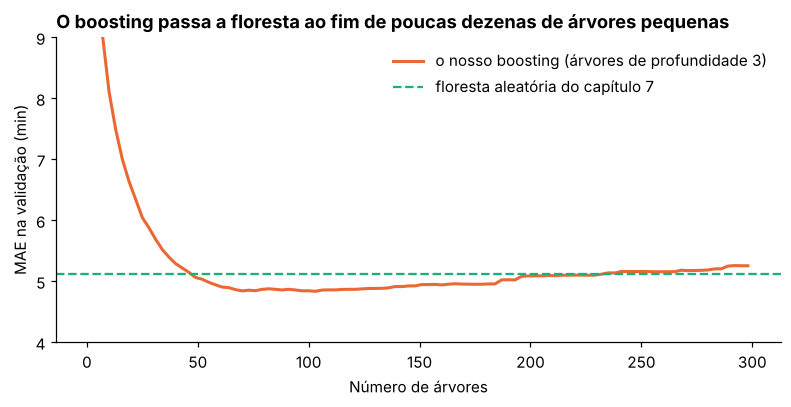

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

numericas, nominais = ["distancia_km", "hora", "paragens", "peso_kg", "chuva"], ["zona", "veiculo"]
tabela = pd.get_dummies(entregas[numericas + nominais], columns=nominais).astype(float)
X_dev, X_teste, y_dev, y_teste = train_test_split(tabela, entregas["tempo_min"], test_size=0.2, random_state=3)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(X_dev, y_dev, test_size=0.25, random_state=0)

nosso = boosting(X_treino, y_treino, n_arvores=300, taxa=0.1, profundidade=3)
erro_por_etapa = [mean_absolute_error(y_validacao, prever_boosting(nosso, X_validacao, n_arvores=n)) for n in range(1, 301, 3)]
floresta = RandomForestRegressor(300, min_samples_leaf=5, max_features=None, random_state=0, n_jobs=-1).fit(X_treino, y_treino)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(range(1, 301, 3), erro_por_etapa, color=LARANJA, lw=2, label="o nosso boosting (árvores de profundidade 3)")
ax.axhline(mean_absolute_error(y_validacao, floresta.predict(X_validacao)), color=VERDE, ls="--", lw=1.5, label="floresta aleatória do capítulo 7")
ax.set_ylim(4, 9)
ax.set_xlabel("Número de árvores")
ax.set_ylabel("MAE na validação (min)")
ax.set_title(f"O boosting passa a floresta ao fim de poucas dezenas de árvores pequenas")
ax.legend(frameon=False)
plt.show()

Com árvores de profundidade 3, que sozinhas seriam modelos fracos, o boosting ultrapassa a floresta de 300 árvores fundas ao fim de cerca de 50. Repara no resto da curva: depois do mínimo, o erro volta a subir devagar e acaba por ficar **acima** do da floresta. O número de árvores tem de ser escolhido.

### As implementações que se usam na prática

A nossa versão e o `GradientBoostingRegressor` procuram a melhor divisão percorrendo todos os valores de cada atributo, o que fica lento com muitos dados. As implementações modernas agrupam primeiro os valores de cada atributo em classes (um **histograma**), e procuram divisões só entre classes. São muito mais rápidas, com resultados equivalentes.

No scikit-learn, é o `HistGradientBoostingRegressor` (e o `HistGradientBoostingClassifier`). Aceita valores em falta sem imputação e tem paragem antecipada incluída. As bibliotecas **XGBoost**, **LightGBM** e **CatBoost**, muito usadas na indústria e em competições, seguem a mesma ideia.

Os hiperparâmetros principais:

| Hiperparâmetro | O que faz | Regra prática |
| --- | --- | --- |
| `learning_rate` | Fração de cada correção que se soma | 0,05 a 0,1; mais baixo exige mais árvores |
| `max_iter` (ou `n_estimators`) | Número de árvores | Um valor alto, com paragem antecipada |
| `max_depth` ou `max_leaf_nodes` | Tamanho de cada árvore | Árvores pequenas: profundidade 2 a 6 |
| `min_samples_leaf` | Mínimo de casos por folha | Aumentar com dados ruidosos |
| `l2_regularization` | Penaliza valores grandes nas folhas | A regularização do módulo 5, aplicada às folhas |

A profundidade das árvores tem um significado próprio no boosting: uma árvore de profundidade 1 usa um atributo de cada vez, e a soma de muitas é um modelo **aditivo**, sem interações. Com profundidade 2, cada árvore pode combinar dois atributos, e o modelo capta interações entre pares.

In [9]:
from sklearn.model_selection import GridSearchCV, KFold

partes = KFold(5, shuffle=True, random_state=0)
grelha = {"learning_rate": [0.03, 0.1], "max_depth": [2, 3, 5], "min_samples_leaf": [10, 30]}
procura = GridSearchCV(HistGradientBoostingRegressor(max_iter=1000, early_stopping=True, random_state=0), grelha, cv=partes, scoring="neg_mean_absolute_error").fit(X_dev, y_dev)
print("Melhor configuração:", procura.best_params_, f"| MAE (validação cruzada): {-procura.best_score_:.2f} min | árvores usadas: {procura.best_estimator_.n_iter_}")

Melhor configuração: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 10} | MAE (validação cruzada): 4.72 min | árvores usadas: 84


## Classificação

Para classificar, o boosting trabalha na escala do **logaritmo das possibilidades**, como a regressão logística do módulo 5: começa com a taxa média da classe positiva, e cada árvore corrige essa pontuação. No fim, a sigmoide converte-a em probabilidade. A perda que se minimiza é a perda logarítmica.

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

a_treino, a_validacao = entregas.loc[X_treino.index, "atrasada"], entregas.loc[X_validacao.index, "atrasada"]
classificadores = {"Regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                   "Árvore afinada": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=0),
                   "Floresta aleatória": RandomForestClassifier(300, min_samples_leaf=2, random_state=0, n_jobs=-1),
                   "Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=1000, early_stopping=True, random_state=0)}
linhas = {}
for nome, modelo in classificadores.items():
    prob = modelo.fit(X_treino, a_treino).predict_proba(X_validacao)[:, 1]
    linhas[nome] = {"AUC": roc_auc_score(a_validacao, prob), "perda logarítmica": log_loss(a_validacao, prob),
                    "melhor F1 (qualquer limiar)": max(f1_score(a_validacao, prob >= t) for t in np.linspace(0.1, 0.7, 25))}
pd.DataFrame(linhas).T.round(3)

,AUC,perda logarítmica,melhor F1 (qualquer limiar)
Regressão logística,0.793,0.377,0.461
Árvore afinada,0.897,0.562,0.739
Floresta aleatória,0.929,0.229,0.779
Boosting,0.942,0.193,0.797


O boosting tem a melhor AUC e a menor perda logarítmica, com a floresta logo a seguir. A regressão logística fica muito atrás: a sua fronteira é uma reta, e os atrasos concentram-se em duas faixas horárias (capítulo 2). A árvore sozinha ordena razoavelmente e tem uma perda logarítmica má, porque as suas folhas dão probabilidades de 0% ou 100% com poucos casos, e a perda castiga essas certezas erradas.

## Bagging e boosting, lado a lado

| | Floresta aleatória (bagging) | Gradient boosting |
| --- | --- | --- |
| As árvores são treinadas | Em paralelo, independentes | Em sequência, cada uma sobre os erros das anteriores |
| Cada árvore é | Funda: pouco viés, muita variância | Pequena: muito viés, pouca variância |
| Juntar árvores reduz | A variância | O viés |
| Mais árvores | Nunca prejudicam | Podem sobreajustar: paragem antecipada |
| Afinação | Pouco exigente | Mais exigente (taxa, número e tamanho das árvores) |
| Sensível a valores extremos e ruído no alvo | Pouco | Mais: insiste nos casos que não consegue acertar |
| Desempenho típico | Muito bom | Muitas vezes o melhor em dados tabulares |

## Os modelos do módulo, no teste

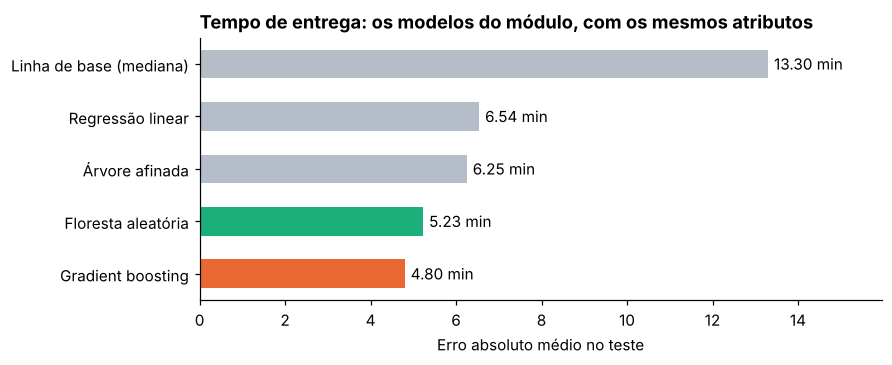

In [11]:
finais = {"Linha de base (mediana)": None, "Regressão linear": LinearRegression(),
          "Árvore afinada": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=0),
          "Floresta aleatória": RandomForestRegressor(300, min_samples_leaf=5, max_features=None, random_state=0, n_jobs=-1),
          "Gradient boosting": procura.best_estimator_}
resultado = {nome: mean_absolute_error(y_teste, np.full(len(y_teste), y_dev.median()) if modelo is None else modelo.fit(X_dev, y_dev).predict(X_teste)) for nome, modelo in finais.items()}

fig, ax = plt.subplots(figsize=(8, 3.1))
barras = ax.barh(list(resultado), list(resultado.values()), color=[CINZA, CINZA, CINZA, VERDE, LARANJA], height=0.55)
ax.bar_label(barras, fmt="%.2f min", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(resultado.values()) * 1.2)
ax.set_xlabel("Erro absoluto médio no teste")
ax.set_title("Tempo de entrega: os modelos do módulo, com os mesmos atributos")
plt.show()

Com os mesmos atributos, cada passo (árvore, floresta, boosting) baixa o erro. A nota do capítulo anterior continua válida: a regressão linear com o atributo `hora_de_ponta`, do capítulo 4, fica ainda abaixo do boosting. O melhor resultado viria de juntar as duas coisas: um bom atributo e um bom modelo.

## Que modelo escolher?

Não há um modelo melhor para tudo. Uma ordem de trabalhos razoável para dados tabulares:

1. **Linha de base** sem modelo (a mediana, a classe mais frequente, a regra atual).
2. **Um modelo linear** (módulo 5): rápido, legível, e diz quanto do problema é simples.
3. **Uma árvore pequena**: para ver regras e descobrir atributos.
4. **Uma floresta aleatória**: um bom resultado com pouca afinação.
5. **Gradient boosting**: quando cada ponto de desempenho conta e há tempo para afinar.

E três perguntas que pesam tanto como o erro:

| Pergunta | Se a resposta for sim |
| --- | --- |
| É preciso **explicar** cada previsão? | Modelo linear ou árvore pequena |
| Os casos novos podem sair **fora** do intervalo dos dados? | Modelo linear; as árvores e os seus conjuntos não extrapolam |
| Há **poucos dados**? | Modelos simples e regularizados; os conjuntos de árvores precisam de dados |

Se um modelo simples fica perto do melhor, é quase sempre a melhor escolha: é mais fácil de explicar, de manter e de corrigir quando falha.

## Exercícios

### `Exercício 1` – Três passos à mão

Tens quatro observações com os alvos 10, 20, 30 e 60. O boosting começa na média e usa uma taxa de aprendizagem de 0,5. A primeira árvore divide as observações em dois grupos, {10, 20} e {30, 60}, e prevê em cada grupo a média dos resíduos. Calcula: (a) a previsão inicial e os resíduos; (b) o que a árvore prevê em cada grupo; (c) as previsões depois do primeiro passo; (d) os novos resíduos.

<details>
<summary><b>Ver uma solução possível</b></summary>

- (a) Média = 30. Resíduos: −20, −10, 0, +30.
- (b) Grupo {10, 20}: média dos resíduos = −15. Grupo {30, 60}: média = +15.
- (c) Previsões: 30 + 0,5 × (−15) = **22,5** para as duas primeiras; 30 + 0,5 × 15 = **37,5** para as outras duas.
- (d) Novos resíduos: −12,5; −2,5; −7,5; +22,5.

Os resíduos diminuíram, sem desaparecer. A árvore seguinte será treinada com estes quatro valores, e provavelmente isolará a última observação, que tem agora o maior resíduo.

</details>

### `Exercício 2` – A profundidade das árvores

Com a função `boosting`, treina três modelos nas entregas (`X_treino`, `y_treino`) com 200 árvores, taxa 0,1 e profundidades 1, 2 e 4. Compara o MAE no treino e na validação. Qual é a melhor profundidade? O que acontece nos dois extremos?

In [12]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for profundidade in [1, 2, 4]:
    m = boosting(X_treino, y_treino, n_arvores=200, taxa=0.1, profundidade=profundidade)
    print(f"profundidade {profundidade}: treino {mean_absolute_error(y_treino, prever_boosting(m, X_treino)):.2f} | validação {mean_absolute_error(y_validacao, prever_boosting(m, X_validacao)):.2f}")
```

A melhor é a profundidade 2. Com profundidade 1, cada árvore usa um só atributo, e a soma de todas é um modelo **aditivo**: o efeito da hora de ponta soma-se ao da distância. Mas nas entregas os efeitos **multiplicam-se** (a hora de ponta atrasa mais as entregas longas). Com profundidade 2, uma árvore pode perguntar pela hora e depois pela distância, e capta essa interação. Com profundidade 4, o erro de treino continua a descer e o de validação **sobe**: 200 árvores deste tamanho já são de mais, e o modelo está a ajustar o ruído. Árvores maiores pedem menos árvores, ou paragem antecipada.

</details>

### `Exercício 3` – Boosting e valores extremos

Cerca de 1,5% das entregas tiveram incidentes e demoraram muito mais. Compara o `HistGradientBoostingRegressor` com `loss="squared_error"` (por omissão) e com `loss="absolute_error"`, medindo o MAE e o RMSE na validação. Qual das perdas dá o melhor MAE? Porquê?

In [13]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for perda in ["squared_error", "absolute_error"]:
    m = HistGradientBoostingRegressor(loss=perda, learning_rate=0.05, max_depth=3, max_iter=1000, early_stopping=True, random_state=0).fit(X_treino, y_treino)
    p = m.predict(X_validacao)
    print(f"{perda:>15}: MAE {mean_absolute_error(y_validacao, p):.2f} | RMSE {np.sqrt(np.mean((y_validacao - p) ** 2)):.2f}")
```

Com a perda absoluta, o MAE baixa. A perda quadrática dá um peso enorme aos incidentes, que nenhum atributo anuncia: o modelo gasta árvores a tentar prevê-los e desvia as previsões das entregas normais. A perda absoluta procura o tempo **típico** (a mediana, capítulo 1) e ignora-os. O modelo treina-se com a perda que corresponde à métrica que interessa.

</details>

### `Exercício 4` – A curva de aprendizagem do boosting

Usa `staged_predict` de um `GradientBoostingRegressor` (500 árvores, taxa 0,1, profundidade 3) para desenhar o MAE no treino e na validação em função do número de árvores. A partir de que ponto o modelo sobreajusta? Quão grave é?

In [14]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
m = GradientBoostingRegressor(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=0).fit(X_treino, y_treino)
treino_etapas = [mean_absolute_error(y_treino, p) for p in m.staged_predict(X_treino)]
validacao_etapas = [mean_absolute_error(y_validacao, p) for p in m.staged_predict(X_validacao)]
plt.plot(treino_etapas, label="treino"); plt.plot(validacao_etapas, label="validação")
plt.xlabel("Número de árvores"); plt.ylabel("MAE (min)"); plt.legend(); plt.show()
print(f"Mínimo na validação: {min(validacao_etapas):.2f} com {int(np.argmin(validacao_etapas)) + 1} árvores | com 500: {validacao_etapas[-1]:.2f}")
```

O erro de treino desce sempre. O de validação desce depressa, atinge um mínimo e depois sobe. Depois do mínimo, por volta das cem árvores, o erro sobe sem parar: com 500, é quase um minuto pior. Nestes dados, os incidentes dão ao boosting muito ruído para perseguir. Escolher o número de árvores (ou usar paragem antecipada) não é um pormenor.

</details>

## Verifica o que aprendeste

- [ ] Sei descrever o boosting como uma sequência de correções.
- [ ] Sei implementar o gradient boosting para regressão.
- [ ] Sei o papel da taxa de aprendizagem e a sua relação com o número de árvores.
- [ ] Sei porque o boosting pode sobreajustar, e como a paragem antecipada o evita.
- [ ] Sei o que muda com a profundidade das árvores.
- [ ] Sei comparar bagging e boosting em termos de viés e de variância.
- [ ] Sei por que ordem experimentar modelos num problema novo.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosted-trees
- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html
- https://en.wikipedia.org/wiki/Gradient_boosting